# JS13 — Praktikum 2: MLP Klasifikasi dengan TensorFlow/Keras (Dataset Iris)

Memakai Keras Sequential untuk klasifikasi bunga iris.

**Tugas 2:** Ubah jumlah neuron hidden layer, bandingkan akurasi dengan konfigurasi awal.

**Tugas 3:** Bandingkan **Sigmoid vs ReLU** pada dataset Iris, catat perbedaan loss dan akurasi.

> **Perbaikan error:** `OneHotEncoder(sparse=False)` sudah dihapus pada scikit-learn ≥ 1.4, diganti dengan `sparse_output=False`.

## Konfigurasi Awal — Hidden Layer (10, 8) dengan ReLU

In [1]:
import numpy as np
import tensorflow as tf
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

tf.keras.utils.set_random_seed(42)

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# One-hot encoding (sparse=False sudah diganti sparse_output=False)
encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Bangun model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

# Kompilasi
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Latih model
h_awal = model.fit(X_train, y_train, epochs=50, batch_size=8, verbose=0)

# Evaluasi
loss_awal, acc_awal = model.evaluate(X_test, y_test, verbose=0)
print(f"Konfigurasi awal (10,8) ReLU -> Loss: {loss_awal:.4f} | Akurasi: {acc_awal:.4f}")

D:\Semester5\ML\244107020017_Machine_Learning\JS05\.venv\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Konfigurasi awal (10,8) ReLU -> Loss: 0.2253 | Akurasi: 0.9667


## Tugas 2 — Mengubah Jumlah Neuron Hidden Layer

Beberapa variasi jumlah neuron dibandingkan dengan konfigurasi awal `(10, 8)`.

In [2]:
def build_and_train(neurons_1, neurons_2, activation='relu', epochs=50):
    tf.keras.utils.set_random_seed(42)
    m = tf.keras.Sequential([
        tf.keras.layers.Dense(neurons_1, activation=activation, input_shape=(4,)),
        tf.keras.layers.Dense(neurons_2, activation=activation),
        tf.keras.layers.Dense(3, activation='softmax')
    ])
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h = m.fit(X_train, y_train, epochs=epochs, batch_size=8, verbose=0)
    loss, acc = m.evaluate(X_test, y_test, verbose=0)
    return h, loss, acc

konfigurasi = [(4, 4), (10, 8), (32, 16), (64, 32)]
hasil_tugas2 = {}

print("Tugas 2 — Perbandingan akurasi vs jumlah neuron hidden layer (ReLU):")
for n1, n2 in konfigurasi:
    h, loss, acc = build_and_train(n1, n2)
    hasil_tugas2[f"({n1},{n2})"] = h
    print(f"  Hidden ({n1},{n2}) -> Loss: {loss:.4f} | Akurasi: {acc:.4f}")

Tugas 2 — Perbandingan akurasi vs jumlah neuron hidden layer (ReLU):


  Hidden (4,4) -> Loss: 0.7727 | Akurasi: 0.7000


  Hidden (10,8) -> Loss: 0.2253 | Akurasi: 0.9667


  Hidden (32,16) -> Loss: 0.0977 | Akurasi: 1.0000


  Hidden (64,32) -> Loss: 0.0947 | Akurasi: 1.0000


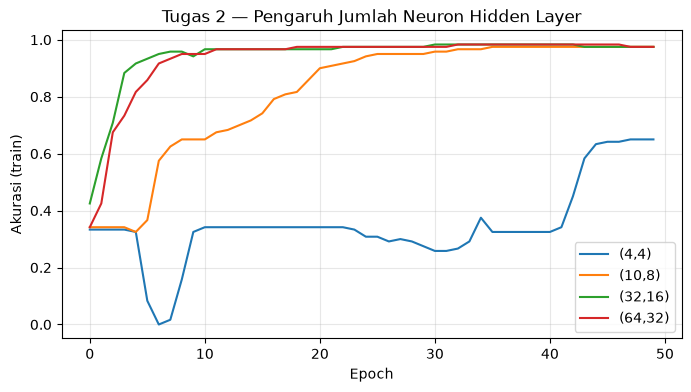

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
for nama, h in hasil_tugas2.items():
    plt.plot(h.history['accuracy'], label=nama)
plt.xlabel('Epoch')
plt.ylabel('Akurasi (train)')
plt.title('Tugas 2 — Pengaruh Jumlah Neuron Hidden Layer')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Tugas 3 — Sigmoid vs ReLU pada Dataset Iris

Arsitektur yang sama `(10, 8)`, hanya fungsi aktivasi hidden layer yang dibedakan.

Tugas 3 — Perbandingan Sigmoid vs ReLU (hidden 10,8):
  Sigmoid -> Loss: 0.6005 | Akurasi: 0.8000
  ReLU    -> Loss: 0.2253 | Akurasi: 0.9667


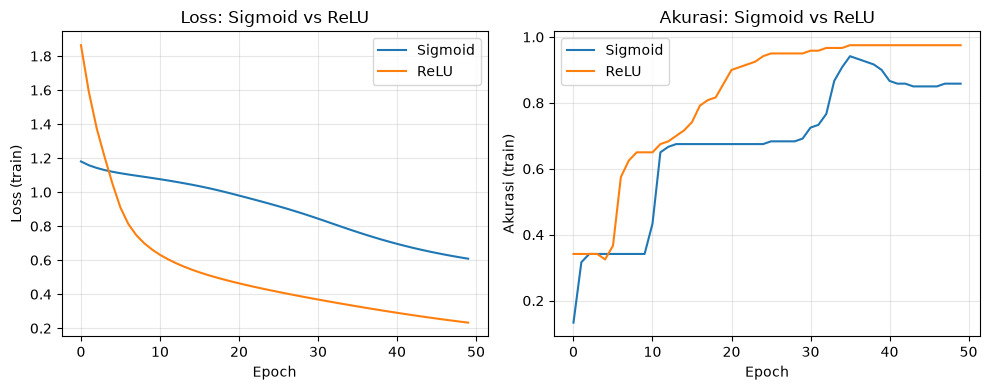

In [4]:
h_sigmoid, loss_sig, acc_sig = build_and_train(10, 8, activation='sigmoid')
h_relu, loss_relu, acc_relu = build_and_train(10, 8, activation='relu')

print("Tugas 3 — Perbandingan Sigmoid vs ReLU (hidden 10,8):")
print(f"  Sigmoid -> Loss: {loss_sig:.4f} | Akurasi: {acc_sig:.4f}")
print(f"  ReLU    -> Loss: {loss_relu:.4f} | Akurasi: {acc_relu:.4f}")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(h_sigmoid.history['loss'], label='Sigmoid')
plt.plot(h_relu.history['loss'], label='ReLU')
plt.xlabel('Epoch'); plt.ylabel('Loss (train)')
plt.title('Loss: Sigmoid vs ReLU'); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(h_sigmoid.history['accuracy'], label='Sigmoid')
plt.plot(h_relu.history['accuracy'], label='ReLU')
plt.xlabel('Epoch'); plt.ylabel('Akurasi (train)')
plt.title('Akurasi: Sigmoid vs ReLU'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Analisis

- **Tugas 2:** jumlah neuron terlalu sedikit (4,4) membuat kapasitas model kecil sehingga akurasi cenderung lebih rendah; menambah neuron meningkatkan kapasitas, tetapi keuntungannya berhenti setelah dataset Iris (yang sederhana) terpelajari dengan baik.
- **Tugas 3:** ReLU umumnya konvergen lebih cepat (loss turun lebih tajam di awal epoch) dibanding sigmoid yang saturasi dan menghasilkan gradien kecil. Pada dataset kecil seperti Iris, akurasi akhir keduanya bisa serupa, tetapi kecepatan konvergensi menjadi pembeda utama.